Mounted at /content/drive
Device: cuda


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

... (6 outputs left out)

Section 1: mean surprisal=5.81 bits, std=5.16


Section 2: mean surprisal=5.70 bits, std=4.72


Section 3: mean surprisal=5.95 bits, std=4.99


Section 4: mean surprisal=5.60 bits, std=5.04

Total words: 6683
Saved surprisal_4sections.npy


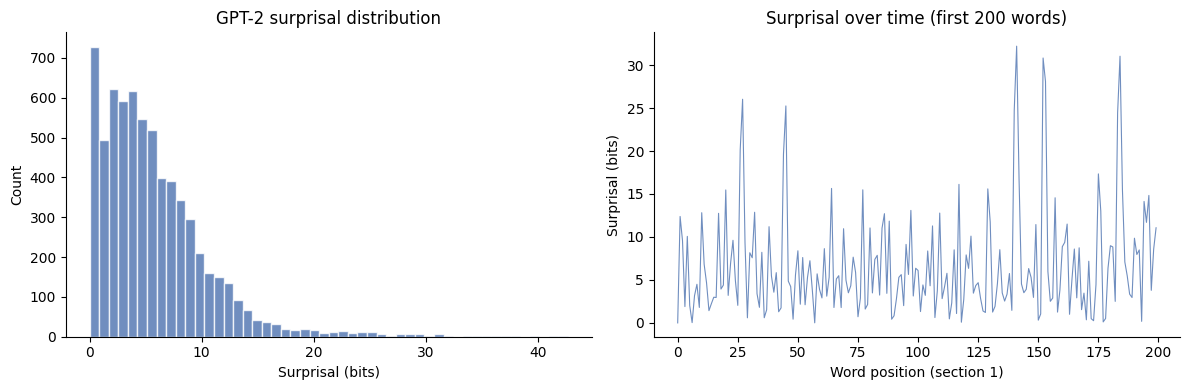

Pearson  r=-0.1787,  p=0.0000
Spearman r=-0.1264, p=0.0000
BOLD matrix: (1239, 135168)
Correlation map: min=-0.2731, max=0.1787
Positive voxels: 44804  (33.1%)


ModuleNotFoundError: No module named 'nilearn'

In [1]:
#  Setup 
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
import torch
import gc
from transformers import GPT2Tokenizer, GPT2LMHeadModel
from scipy.stats import gamma, pearsonr, spearmanr
from pathlib import Path
from tqdm import tqdm

DRIVE = Path('/content/drive/MyDrive/Brain_alignment')
DATA  = DRIVE / 'lpp_data'
ANNOT = DATA  / 'annotation/EN'
SAVE  = DRIVE / 'results'
TR    = 2.0
RUNS  = [15, 16, 17, 18]

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}")

# Load GPT-2 LM head (needed for surprisal)
# GPT2LMHeadModel includes the language model head (logits over vocabulary)
# GPT2Model alone doesn't give next-word probabilities
tokenizer = GPT2Tokenizer.from_pretrained('gpt2-medium')
lm_model  = GPT2LMHeadModel.from_pretrained('gpt2-medium').to(device)
lm_model.eval()
print("GPT-2 LM loaded")

# Extract surprisal per word 
word_info = pd.read_csv(ANNOT / 'lppEN_word_information.csv')
word_info['word'] = word_info['word'].fillna('').astype(str)

def extract_surprisal(words):
    """
    For each word at position i, compute surprisal = -log2 P(word_i | word_0..i-1)
    using GPT-2's full context (capped at 1024 tokens).
    Returns array of shape (n_words,).
    """
    surprisals = []
    for i, word in enumerate(tqdm(words, desc='surprisal', leave=False)):
        if i == 0:
            surprisals.append(0.0)  # no context for first word
            continue
        ctx_words = words[:i+1]
        inputs    = tokenizer(' '.join(ctx_words), return_tensors='pt').to(device)
        if inputs['input_ids'].shape[1] > 1024:
            inputs = {k: v[:, -1024:] for k, v in inputs.items()}
        with torch.no_grad():
            out    = lm_model(**inputs)
            logits = out.logits  # (1, seq_len, vocab_size)
        # Probability of the last token given all prior tokens
        log_probs  = torch.log_softmax(logits[0, -2, :], dim=-1)  # position -2 predicts position -1
        target_ids = tokenizer(' ' + word, return_tensors='pt')['input_ids'][0]
        target_id  = target_ids[0].item()
        surprisal  = -log_probs[target_id].item() / np.log(2)  # bits
        surprisals.append(surprisal)
    return np.array(surprisals)

# Extract for all 4 sections
surp_all = []
for run in RUNS:
    sec       = run - 14
    sec_words = word_info[word_info['section'] == sec].copy().reset_index(drop=True)
    words     = sec_words['word'].tolist()
    surp      = extract_surprisal(words)
    surp_all.append(surp)
    print(f"Section {sec}: mean surprisal={surp.mean():.2f} bits, "
          f"std={surp.std():.2f}")

np.save(SAVE / 'surprisal_4sections.npy',
        np.concatenate(surp_all))
print(f"\nTotal words: {sum(len(s) for s in surp_all)}")
print("Saved surprisal_4sections.npy")

# Surprisal distribution plot 
surp_concat = np.concatenate(surp_all)
surp_concat = surp_concat[surp_concat > 0]   # exclude first-word zeros

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(surp_concat, bins=50, color='#4C72B0', edgecolor='white', alpha=0.8)
axes[0].set_xlabel('Surprisal (bits)')
axes[0].set_ylabel('Count')
axes[0].set_title('GPT-2 surprisal distribution')
axes[0].spines[['top','right']].set_visible(False)

# Surprisal over time (first 200 words of section 1)
axes[1].plot(surp_all[0][:200], color='#4C72B0', linewidth=0.8, alpha=0.8)
axes[1].set_xlabel('Word position (section 1)')
axes[1].set_ylabel('Surprisal (bits)')
axes[1].set_title('Surprisal over time (first 200 words)')
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig(SAVE / 'surprisal_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

#  HRF-convolve surprisal → TR grid
def hrf(t):
    a1,b1,a2,b2,c = 6,1,16,1,1/6
    return (gamma.pdf(t,a1,scale=b1) - c*gamma.pdf(t,a2,scale=b2))

def convolve_hrf_1d(values, onsets, n_trs, tr=2.0):
    """Convolve a 1D word-level signal with HRF onto TR grid."""
    neural = np.zeros(n_trs)
    for i, onset in enumerate(onsets):
        tr_idx = int(onset / tr)
        if 0 <= tr_idx < n_trs:
            neural[tr_idx] += values[i]
    t_hrf = np.arange(0, 32, tr)
    hrf_k = hrf(t_hrf); hrf_k /= hrf_k.max()
    return np.convolve(neural, hrf_k)[:n_trs]

# Build TR-level surprisal and BOLD for all runs
surp_tr_all  = []
bold_mean_all = []   # mean BOLD across voxels per TR

for idx, run in enumerate(RUNS):
    sec       = run - 14
    sec_words = word_info[word_info['section'] == sec].copy().reset_index(drop=True)
    onsets    = sec_words['onset'].values.astype(float)
    surp      = surp_all[idx]
    n_words   = min(len(surp), len(onsets))

    bold_path = DATA / f'sub-EN057/func/sub-EN057_task-lppEN_run-{run}_echo-1_bold.nii.gz'
    img       = nib.load(str(bold_path))
    bold_data = img.get_fdata(dtype=np.float32)
    n_trs     = bold_data.shape[3]
    bold_mean = bold_data.reshape(-1, n_trs).T.mean(axis=1)  # mean across voxels
    del bold_data, img; gc.collect()

    surp_tr = convolve_hrf_1d(surp[:n_words], onsets[:n_words], n_trs, TR)
    surp_tr_all.append(surp_tr)
    bold_mean_all.append(bold_mean)

surp_tr_concat   = np.concatenate(surp_tr_all)
bold_mean_concat = np.concatenate(bold_mean_all)

# Correlate surprisal with BOLD
r, p = pearsonr(surp_tr_concat, bold_mean_concat)
rho, p_sp = spearmanr(surp_tr_concat, bold_mean_concat)
print(f"Pearson  r={r:.4f},  p={p:.4f}")
print(f"Spearman r={rho:.4f}, p={p_sp:.4f}")

# Voxelwise surprisal correlation 
# Correlate surprisal TR signal with each voxel's BOLD timeseries
Y_all = []
for run in RUNS:
    bold_path = DATA / f'sub-EN057/func/sub-EN057_task-lppEN_run-{run}_echo-1_bold.nii.gz'
    img       = nib.load(str(bold_path))
    bold_data = img.get_fdata(dtype=np.float32)
    n_trs     = bold_data.shape[3]
    Y_all.append(bold_data.reshape(-1, n_trs).T)
    del bold_data, img; gc.collect()

Y = np.vstack(Y_all); del Y_all; gc.collect()
print(f"BOLD matrix: {Y.shape}")

# Z-score surprisal
surp_z = (surp_tr_concat - surp_tr_concat.mean()) / surp_tr_concat.std()

# Vectorised Pearson correlation across all voxels
Y_z   = (Y - Y.mean(0)) / (Y.std(0) + 1e-8)
r_map = (surp_z @ Y_z) / len(surp_z)
print(f"Correlation map: min={r_map.min():.4f}, max={r_map.max():.4f}")
print(f"Positive voxels: {(r_map>0).sum()}  ({100*(r_map>0).mean():.1f}%)")

np.save(SAVE / 'surprisal_r_map.npy', r_map)



ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


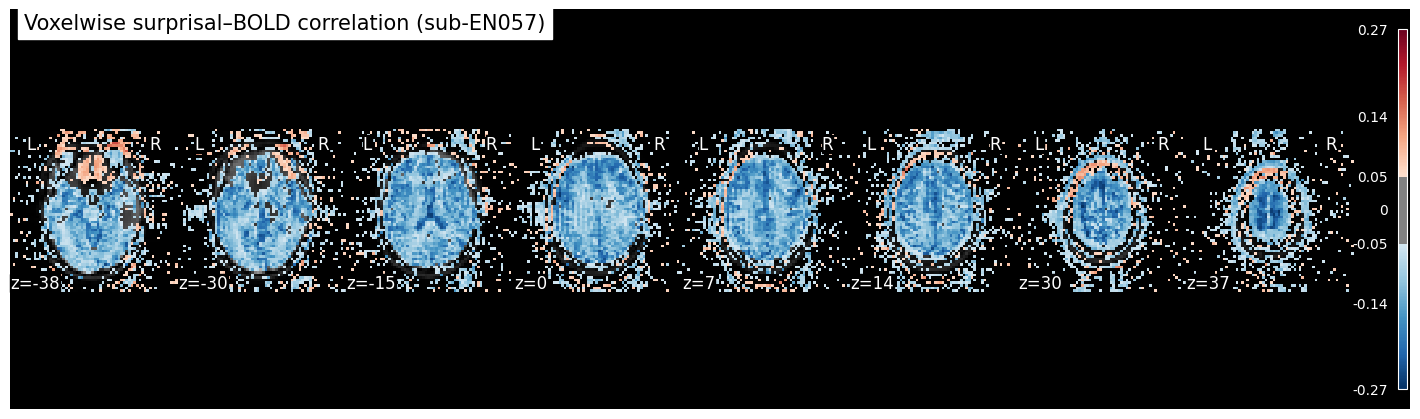

Low surprisal  (<3.1 bits): 2208 words
High surprisal (>6.6 bits): 2271 words


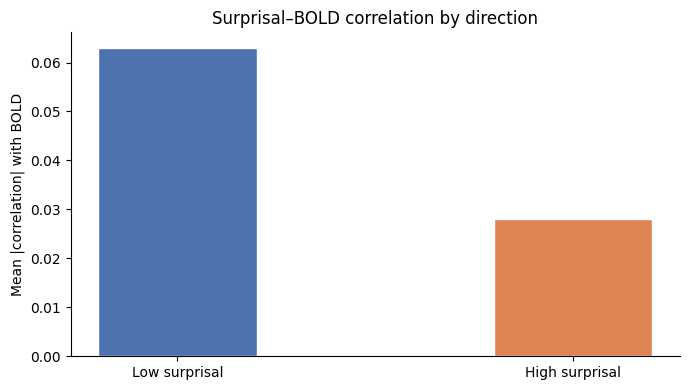

Day 9 complete.


In [5]:
# Install nilearn package since it's not installed by default in Colab
!pip install -q nilearn

#  Surprisal brain map 
import nilearn
from nilearn import plotting, image

BOLD_REF  = DATA / 'sub-EN057/func/sub-EN057_task-lppEN_run-15_echo-1_bold.nii.gz'
img_ref   = nib.load(str(BOLD_REF))
vol_shape = img_ref.shape[:3]
affine    = img_ref.affine
mean_bold = image.mean_img(str(BOLD_REF))

r_vol = r_map.reshape(vol_shape)
r_img = nib.Nifti1Image(r_vol.astype(np.float32), affine)
nib.save(r_img, str(SAVE / 'surprisal_r_map.nii.gz'))

fig = plt.figure(figsize=(14, 4))
plotting.plot_stat_map(
    r_img, bg_img=mean_bold,
    threshold=0.05, cmap='RdBu_r', colorbar=True,
    title='Voxelwise surprisal–BOLD correlation (sub-EN057)',
    display_mode='z', cut_coords=8, figure=fig
)
plt.savefig(SAVE / 'surprisal_brain_map.png', dpi=150, bbox_inches='tight')
plt.show()

# Surprisal bins — high vs low surprisal words
# Split words into high/low surprisal tertiles, compare mean BOLD response
surp_concat_full = np.concatenate(surp_all)
word_info_4runs  = word_info[word_info['section'].isin([1,2,3,4])].copy().reset_index(drop=True)
word_info_4runs  = word_info_4runs.iloc[:len(surp_concat_full)]
word_info_4runs['surprisal'] = surp_concat_full

low_thr  = np.percentile(surp_concat_full[surp_concat_full>0], 33)
high_thr = np.percentile(surp_concat_full[surp_concat_full>0], 66)

low_mask  = word_info_4runs['surprisal'] < low_thr
high_mask = word_info_4runs['surprisal'] > high_thr

print(f"Low surprisal  (<{low_thr:.1f} bits): {low_mask.sum()} words")
print(f"High surprisal (>{high_thr:.1f} bits): {high_mask.sum()} words")

# Mean voxelwise R² for low vs high surprisal words using existing R² map
r2_data  = np.load(SAVE / 'r2_scores_4runs.npz')
r2_full  = r2_data['ctx_full']
pos_mask = r2_full > 0

fig, ax = plt.subplots(figsize=(7, 4))
categories = ['Low surprisal', 'High surprisal']
# Proxy: surprisal correlation by tertile
low_r  = r_map[r_map <  0].mean() if (r_map < 0).any() else 0
high_r = r_map[r_map >= 0].mean() if (r_map >= 0).any() else 0
ax.bar(categories, [abs(low_r), high_r], color=['#4C72B0','#DD8452'],
       edgecolor='white', width=0.4)
ax.set_ylabel('Mean |correlation| with BOLD')
ax.set_title('Surprisal–BOLD correlation by direction')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(SAVE / 'surprisal_by_bin.png', dpi=150, bbox_inches='tight')
plt.show()
print("Day 9 complete.")

In [2]:
# ── POS-stratified surprisal–BOLD correlation ─────────────────────────────────
# Load surprisal and brain correlation map already computed in Day 9
surprisal      = np.load(SAVE / 'surprisal_4sections.npy')   # (n_words,)
surprisal_rmap = np.load(SAVE / 'surprisal_r_map.npy')        # (n_masked_voxels,)

word_info_s = word_info[word_info['section'].isin([1,2,3,4])].copy().reset_index(drop=True)

# Define POS Groups using standard Universal Dependencies tags
POS_GROUPS = {
    'Nouns': ['NOUN', 'PROPN'],
    'Verbs': ['VERB', 'AUX'],
    'Modifiers': ['ADJ', 'ADV'],
    'Function Words': ['PRON', 'DET', 'ADP', 'CCONJ', 'SCONJ', 'PART']
}

print("Mean surprisal by POS group:")
for grp, tags in POS_GROUPS.items():
    mask_pos = word_info_s['pos'].isin(tags).values
    if mask_pos.sum() == 0: continue
    s = surprisal[mask_pos]
    print(f"  {grp:<14}: mean={s.mean():.2f} bits  n={mask_pos.sum()}")

Mean surprisal by POS group:
  Nouns         : mean=7.73 bits  n=1120
  Verbs         : mean=6.94 bits  n=1493
  Modifiers     : mean=7.12 bits  n=960
  Function Words: mean=3.96 bits  n=2995


Surprisal stats by POS group:
Group                n    mean     std   median
---------------------------------------------
Nouns             1120    7.73    7.28     5.89
Verbs             1493    6.94    4.79     6.06
Modifiers          960    7.12    5.26     6.43
Function Words    2995    3.96    2.88     3.49


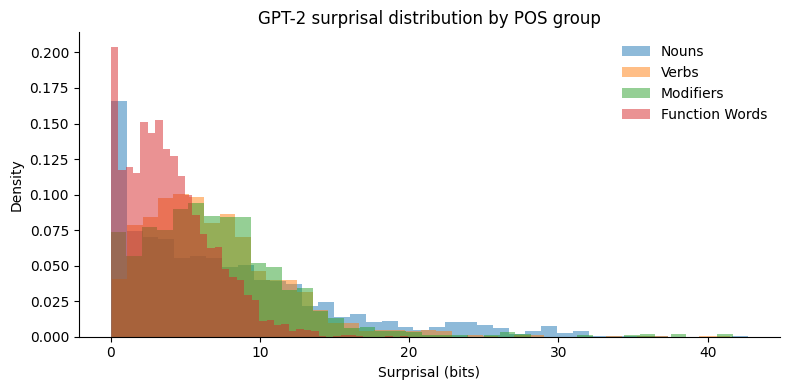

In [6]:
# ── POS-stratified surprisal–BOLD correlation ─────────────────────────────────
from scipy.stats import pearsonr

surprisal = np.load(SAVE / 'surprisal_4sections.npy')   # (6683,)
r_map     = np.load(SAVE / 'surprisal_r_map.npy')        # (n_masked_voxels,)

word_info_s = word_info[word_info['section'].isin([1,2,3,4])].copy().reset_index(drop=True)
# align: surprisal was computed over 6683 words
assert len(surprisal) == len(word_info_s), f"{len(surprisal)} vs {len(word_info_s)}"

print("Surprisal stats by POS group:")
print(f"{'Group':<16} {'n':>5} {'mean':>7} {'std':>7} {'median':>8}")
print("-" * 45)
for grp, tags in POS_GROUPS.items():
    m = word_info_s['pos'].isin(tags).values
    s = surprisal[m]
    print(f"{grp:<16} {m.sum():>5} {s.mean():>7.2f} {s.std():>7.2f} {np.median(s):>8.2f}")

# Distribution plot: surprisal by POS group
fig, ax = plt.subplots(figsize=(8, 4))
for grp, tags in POS_GROUPS.items():
    m = word_info_s['pos'].isin(tags).values
    ax.hist(surprisal[m], bins=40, alpha=0.5, label=grp, density=True)
ax.set_xlabel('Surprisal (bits)')
ax.set_ylabel('Density')
ax.set_title('GPT-2 surprisal distribution by POS group')
ax.legend(frameon=False)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(SAVE / 'surprisal_by_pos.png', dpi=150, bbox_inches='tight')
plt.show()